<a href="https://colab.research.google.com/github/MiikanGod/Classification/blob/main/Klasifikasi_Multiclass_(Pokemon).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [17]:
# ==============================================================================
# 1. IMPORT LIBRARY & UPLOAD FILE
# ==============================================================================
import os
import zipfile
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from PIL import Image
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
import tensorflow as tf
from tensorflow.keras import layers, models

from google.colab import files

print('--- 1. UPLOAD FILE CSV (pokemon.csv) ---')
uploaded_csv = files.upload()

print('\n--- 2. UPLOAD FILE ZIP GAMBAR (images.zip) ---')
uploaded_zip = files.upload()

# Ekstrak images.zip ke dalam folder 'images'
if os.path.exists('images.zip'):
  with zipfile.ZipFile('images.zip', 'r') as zip_ref:
    zip_ref.extractall('.')
  print('Berhasil mengekstrak folder gambar!')

--- 1. UPLOAD FILE CSV (pokemon.csv) ---


Saving pokemon.csv to pokemon (2).csv

--- 2. UPLOAD FILE ZIP GAMBAR (images.zip) ---


Saving images.zip to images (2).zip
Berhasil mengekstrak folder gambar!


In [26]:
# ==============================================================================
# 2. MATCHING CITRA DENGAN CSV & PREPROCESSING 128x128
# ==============================================================================
df_pokemon = pd.read_csv('pokemon.csv')
image_folder = 'images'

valid_images = []
valid_labels = []

for idx, row in df_pokemon.iterrows():
  name = str(row['Name']).lower().strip()
  type1 = row['Type1']

  img_path = None
  for ext in ['.png', '.jpg', '.jpeg']:
    possible_path = os.path.join(image_folder, f'{name}{ext}')
    if os.path.exists(possible_path):
      img_path = possible_path
      break

  if img_path:
    valid_images.append(img_path)
    valid_labels.append(type1)

df_clean = pd.DataFrame({'image_path': valid_images, 'Type1': valid_labels})

le = LabelEncoder()
df_clean['target'] = le.fit_transform(df_clean['Type1'])
num_classes = len(le.classes_)


# Fungsi muat dan resize gambar ke 128x128 piksel
def load_and_preprocess_image(path, target_size=(128, 128)):
  img = Image.open(path).convert('RGB')
  img = img.resize(target_size)
  return np.array(img) / 255.0  # Normalisasi piksel ke [0, 1]


print('Sedang memproses seluruh gambar ke resolusi 128x128 piksel...')
X = np.array([load_and_preprocess_image(p) for p in df_clean['image_path']])
y = df_clean['target'].values

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

Sedang memproses seluruh gambar ke resolusi 128x128 piksel...


In [27]:
# ==============================================================================
# 3. KELOLA DAN LATIH MODEL CNN (128x128)
# ==============================================================================
model = models.Sequential([
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(128, 128, 3)),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D((2, 2)),
    layers.Flatten(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.3),
    layers.Dense(num_classes, activation='softmax'),
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy'],
)

print('\nSedang melatih model CNN 128x128...')
history = model.fit(
    X_train, y_train, epochs=20, batch_size=32, validation_data=(X_test, y_test)
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Sedang melatih model CNN 128x128...
Epoch 1/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 26s 1s/step - accuracy: 0.1206 - loss: 2.8173 - val_accuracy: 0.1667 - val_loss: 2.7233
Epoch 2/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.1762 - loss: 2.6670 - val_accuracy: 0.1914 - val_loss: 2.6248
Epoch 3/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.2334 - loss: 2.4905 - val_accuracy: 0.1790 - val_loss: 2.6420
Epoch 4/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 39s 976ms/step - accuracy: 0.2875 - loss: 2.3218 - val_accuracy: 0.2037 - val_loss: 2.6559
Epoch 5/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.3756 - loss: 1.9919 - val_accuracy: 0.2099 - val_loss: 2.7660
Epoch 6/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 980ms/step - accuracy: 0.4946 - loss: 1.5652 - val_accuracy: 0.2037 - val_loss: 2.8294
Epoch 7/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 22s 1s/step - accuracy: 0.6522 - loss: 1.1133 - val_accuracy: 0.2284 - val_loss: 3.1472
Epoch 8/20
21/21 ━━━━━━━━━━━━━━━━━━━━ 20s 980ms/step - accuracy: 0.7249 - l

6/6 ━━━━━━━━━━━━━━━━━━━━ 4s 604ms/step

 AKURASI MULTI-CLASS (CNN 128x128): 15.43%

Classification Report:
              precision    recall  f1-score   support

         Bug       0.25      0.14      0.18        14
        Dark       0.00      0.00      0.00         6
      Dragon       0.00      0.00      0.00         5
    Electric       0.00      0.00      0.00         8
       Fairy       0.00      0.00      0.00         4
    Fighting       0.20      0.17      0.18         6
        Fire       0.60      0.55      0.57        11
       Ghost       0.20      0.20      0.20         5
       Grass       0.13      0.12      0.13        16
      Ground       0.00      0.00      0.00         6
         Ice       1.00      0.20      0.33         5
      Normal       0.24      0.33      0.28        21
      Poison       1.00      0.14      0.25         7
     Psychic       0.00      0.00      0.00        11
        Rock       0.00      0.00      0.00         9
       Steel       0.00     

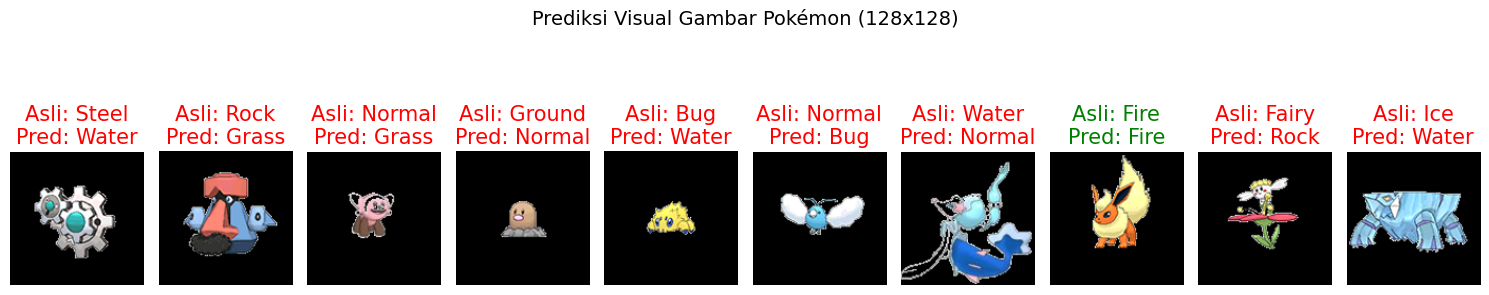

In [40]:
# ==============================================================================
# 4. EVALUASI DAN VISUALISASI
# ==============================================================================
y_pred_probs = model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

present_labels = np.unique(np.concatenate([y_test, y_pred]))

acc = accuracy_score(y_test, y_pred)
print(f'\n==================================================')
print(f' AKURASI MULTI-CLASS (CNN 128x128): {acc * 100:.2f}%')
print(f'==================================================\n')

print('Classification Report:')
print(
    classification_report(
        y_test,
        y_pred,
        labels=present_labels,
        target_names=le.classes_[present_labels],
        zero_division=0,
    )
)

# Visualisasi Prediksi Gambar
num_samples = 10
plt.figure(figsize=(15, 4))
for i in range(num_samples):
  plt.subplot(1, num_samples, i + 1)
  plt.imshow(X_test[i])
  plt.axis('off')

  actual_class = le.inverse_transform([y_test[i]])[0]
  predicted_class = le.inverse_transform([y_pred[i]])[0]
  color = 'green' if actual_class == predicted_class else 'red'

  plt.title(
      f'Asli: {actual_class}\nPred: {predicted_class}',
      color=color,
      fontsize=15,
  )

plt.suptitle('Prediksi Visual Gambar Pokémon (128x128)', fontsize=14)
plt.tight_layout()
plt.show()